# Mini Project: Image Colorization (ภาพวาดสเก็ต -> เติมสีให้ภาพ)
### วิชา Deep Learning
**สมาชิกกลุ่ม (2 คน):**
1. ชื่อ-นามสกุล: นายสัพพัญญู คำตุ้ม รหัสนักศึกษา: 673380066-4
2. ชื่อ-นามสกุล: นายจิณณวัตร โพธิ์ศรีทอง  รหัสนักศึกษา: 673380263-2

---
### สรุปสาระสำคัญของโครงงาน:
- **หัวข้อภาพ:** ผลไม้และพืชธรรมชาติ 3 หมวดหมู่ ได้แก่ Apple (แอปเปิ้ล), Carrot (แครอท), และ Flower (ดอกไม้)
- **จำนวนข้อมูล:** ทั้งหมด 60 คู่ภาพ (วาดสเก็ตเองและลงสีเป้าหมายเอง สมาชิก 2 คน คนละ 30 คู่)
- **โมเดลที่ใช้:** U-Net Architecture (Encoder-Decoder with Skip Connections) สำหรับงาน Image-to-Image Translation
- **การวัดประสิทธิภาพ:** Mean Absolute Error (MAE) และ Peak Signal-to-Noise Ratio (PSNR)

## 0. เตรียมข้อมูลสำหรับ Google Colab
*(หากรันบนเครื่องตนเอง (Local) สามารถกดข้ามเซลล์นี้ไปรันข้อ 1 ได้เลย)*

💡 **วิธีที่ง่ายและเร็วที่สุด (แนะนำ - ใช้เวลาเพียง 5 วินาที):**
1. คลิกไอคอน **โฟลเดอร์ 📁 (Files)** ที่แถบด้านซ้ายของ Google Colab
2. ลากไฟล์ `ข้อมูลภาพ.zip` จากในเครื่องของคุณ (ขนาดเพียง ~300 KB) ไปวางในช่อง Files
3. กดรันเซลล์ด้านล่างนี้ โค้ดจะแตกไฟล์และเตรียมชุดข้อมูลให้อัตโนมัติทันที

In [1]:
# โค้ดเตรียมข้อมูลใน Google Colab
import os
import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print(' กำลังทำงานบน Google Colab')

    # ตรวจสอบไฟล์ ข้อมูลภาพ.zip ใน Colab
    zip_candidates = ['ข้อมูลภาพ.zip', '/content/ข้อมูลภาพ.zip']
    found_zip = None
    for z in zip_candidates:
        if os.path.exists(z):
            found_zip = z
            break

    if found_zip:
        print(f' พบไฟล์ {found_zip} กำลังแตกไฟล์...')
        !unzip -o -q "{found_zip}"
        print(' แตกไฟล์ Dataset สำเร็จพร้อมใช้งานทันที!')
    elif os.path.exists('/content/dataset/sketch') or os.path.exists('/content/DataSet/sketch'):
        print(' พบโฟลเดอร์ Dataset เรียบร้อยแล้ว พร้อมทำงานต่อได้เลย')
    else:
        print('⚠️ ยังไม่พบไฟล์ข้อมูลภาพใน Colab')
        print('👉 ให้ลากไฟล์ "ข้อมูลภาพ.zip" จากคอมพิวเตอร์ มาวางที่แท็บ Files 📁 ด้านซ้าย แล้วกดรันเซลล์นี้ใหม่อีกครั้งครับ')
else:
    print(' รันบนเครื่อง Local: พร้อมใช้งานชุดข้อมูลในเครื่อง')

 กำลังทำงานบน Google Colab
 พบไฟล์ ข้อมูลภาพ.zip กำลังแตกไฟล์...
 แตกไฟล์ Dataset สำเร็จพร้อมใช้งานทันที!


## 1. Import ไลบรารีที่จำเป็นและตรวจสอบ GPU

In [2]:
import os
import glob
import math
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms

# ตรวจสอบ Device (GPU หรือ CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if torch.cuda.is_available():
    print(f'GPU Name: {torch.cuda.get_device_name(0)}')
else:
    print('Tip: แนะนำเปิด GPU บน Colab ที่ Runtime -> Change runtime type -> T4 GPU')

Using device: cuda
GPU Name: Tesla T4


## 2. การเตรียมข้อมูล (Data Preparation & Dataset Class)
ค้นหาโฟลเดอร์ `sketch` (Input) และ `color` (Target) โดยอัตโนมัติ (รองรับทั้ง Colab, Google Drive, และ Local)

In [3]:
def find_dataset_dirs():
    """ฟังก์ชันค้นหาโฟลเดอร์ sketch และ color แบบอัตโนมัติ"""
    candidates = [
        ('DataSet/sketch', 'DataSet/color'),
        ('dataset/sketch', 'dataset/color'),
        ('/content/dataset_gdrive/sketch', '/content/dataset_gdrive/color'),
        ('/content/dataset_gdrive/DataSet/sketch', '/content/dataset_gdrive/DataSet/color'),
        ('/content/dataset_gdrive/dataset/sketch', '/content/dataset_gdrive/dataset/color'),
        ('/content/dataset/sketch', '/content/dataset/color'),
        ('/content/DataSet/sketch', '/content/DataSet/color'),
        ('/content/drive/MyDrive/DataSet/sketch', '/content/drive/MyDrive/DataSet/color'),
        ('/content/drive/MyDrive/dataset/sketch', '/content/drive/MyDrive/dataset/color'),
    ]
    for s_cand, c_cand in candidates:
        if os.path.exists(s_cand) and os.path.exists(c_cand):
            if len(os.listdir(s_cand)) > 0 and len(os.listdir(c_cand)) > 0:
                return s_cand, c_cand

    # ค้นหาแบบ Recursive
    search_roots = ['/content', '.', '..', '/content/drive/MyDrive']
    for root in search_roots:
        if not os.path.exists(root):
            continue
        for r, dirs, files in os.walk(root):
            if 'sketch' in dirs and 'color' in dirs:
                s_path = os.path.join(r, 'sketch')
                c_path = os.path.join(r, 'color')
                if len(os.listdir(s_path)) > 0 and len(os.listdir(c_path)) > 0:
                    return s_path, c_path

    raise FileNotFoundError("ไม่พบโฟลเดอร์ sketch และ color กรุณาตรวจสอบตำแหน่งไฟล์")

sketch_dir, color_dir = find_dataset_dirs()
print(f" โฟลเดอร์ Sketch: {sketch_dir}")
print(f" โฟลเดอร์ Color:  {color_dir}")

# กรองเฉพาะไฟล์ภาพ (.png, .jpg, .jpeg)
valid_exts = ('.png', '.jpg', '.jpeg')
filenames = sorted([f for f in os.listdir(sketch_dir) if f.lower().endswith(valid_exts)])

all_sketches = [os.path.join(sketch_dir, f) for f in filenames]
all_colors = [os.path.join(color_dir, f) for f in filenames]

print(f" โหลดคู่ภาพสำเร็จทั้งหมด: {len(all_sketches)} คู่")

 โฟลเดอร์ Sketch: dataset/sketch
 โฟลเดอร์ Color:  dataset/color
 โหลดคู่ภาพสำเร็จทั้งหมด: 60 คู่


In [4]:
class ColorizationDataset(Dataset):
    def __init__(self, sketch_paths, color_paths, transform=None):
        self.sketch_paths = sketch_paths
        self.color_paths = color_paths
        self.transform = transform

    def __len__(self):
        return len(self.sketch_paths)

    def __getitem__(self, idx):
        sketch = Image.open(self.sketch_paths[idx]).convert('RGB')
        color = Image.open(self.color_paths[idx]).convert('RGB')

        if self.transform:
            sketch = self.transform(sketch)
            color = self.transform(color)

        return sketch, color, os.path.basename(self.sketch_paths[idx])

# แปลงขนาดภาพเป็น 128x128 และ Normalize พิกเซลให้อยู่ในช่วง [-1, 1]
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

### แสดงตัวอย่างภาพในชุดข้อมูล (Sketch vs Target Color)

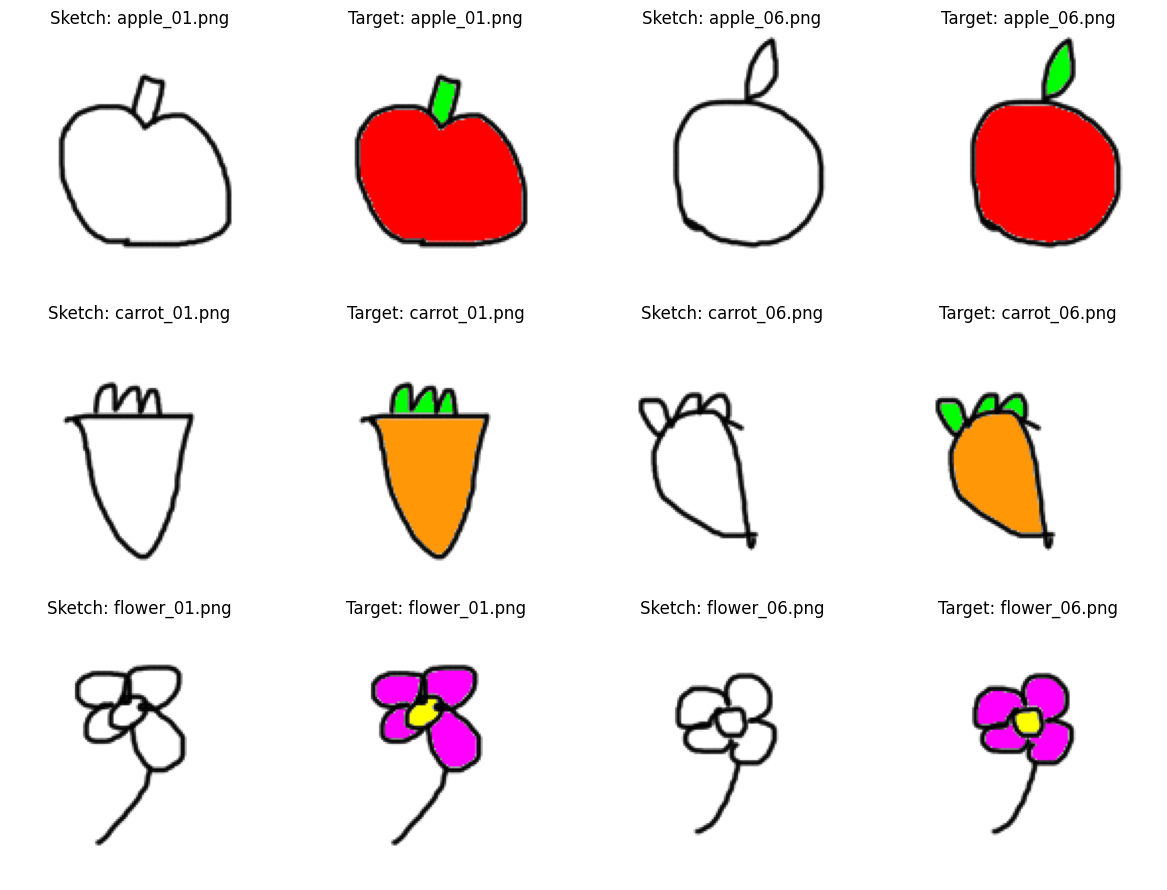

In [5]:
def denormalize(tensor):
    """แปลงค่า Tensor [-1, 1] กลับเป็นภาพช่วง [0, 1] เพื่อแสดงผล"""
    return (tensor * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0).cpu().numpy()

sample_dataset = ColorizationDataset(all_sketches, all_colors, transform=transform)
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
sample_indices = [0, 5, 20, 25, 40, 45]  # สุ่มดูตัวอย่างหมวดหมู่ Apple, Carrot, Flower

for i, idx in enumerate(sample_indices):
    if idx >= len(sample_dataset):
        break
    s_tensor, c_tensor, name = sample_dataset[idx]
    row = i // 2
    col_s = (i % 2) * 2
    col_c = col_s + 1

    axes[row, col_s].imshow(denormalize(s_tensor))
    axes[row, col_s].set_title(f'Sketch: {name}')
    axes[row, col_s].axis('off')

    axes[row, col_c].imshow(denormalize(c_tensor))
    axes[row, col_c].set_title(f'Target: {name}')
    axes[row, col_c].axis('off')

plt.tight_layout()
plt.show()

## 3. การแบ่ง Train / Test Split
- แบ่งชุดข้อมูลเป็น 80% สำหรับ Train (48 คู่ภาพ)
- และ 20% สำหรับ Test (12 คู่ภาพ) เพื่อวัดประสิทธิภาพของโมเดลบนภาพที่ไม่เคยเห็นมาก่อน

In [6]:
np.random.seed(42)
indices = np.arange(len(all_sketches))
np.random.shuffle(indices)

split_point = int(0.8 * len(indices))
train_indices = indices[:split_point]
test_indices = indices[split_point:]

train_sketches = [all_sketches[i] for i in train_indices]
train_colors = [all_colors[i] for i in train_indices]
test_sketches = [all_sketches[i] for i in test_indices]
test_colors = [all_colors[i] for i in test_indices]

train_dataset = ColorizationDataset(train_sketches, train_colors, transform=transform)
test_dataset = ColorizationDataset(test_sketches, test_colors, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False)

print(f'Train samples: {len(train_dataset)} pairs')
print(f'Test samples:  {len(test_dataset)} pairs')

Train samples: 48 pairs
Test samples:  12 pairs


## 4. โครงสร้างโมเดล (U-Net Architecture)
ใช้สถาปัตยกรรม **U-Net** ซึ่งประกอบด้วย:
1. **Contracting Path (Encoder):** สกัดลักษณะเด่นของลายเส้นสเก็ต
2. **Bottleneck:** รวมคุณลักษณะเชิงลึก (latent feature representation)
3. **Expansive Path (Decoder):** ขยายมิติภาพกลับเป็น 128x128 3 Channels (RGB)
4. **Skip Connections:** ส่งผ่านโครงสร้างเส้นสเก็ตข้าม Layer ตรงไปยัง Decoder ช่วยให้เส้นขอบและรูปทรงคงความคมชัด

In [7]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UNetColorizer(nn.Module):
    def __init__(self):
        super().__init__()
        # Encoder
        self.e1 = ConvBlock(3, 32)
        self.p1 = nn.MaxPool2d(2)
        self.e2 = ConvBlock(32, 64)
        self.p2 = nn.MaxPool2d(2)
        self.e3 = ConvBlock(64, 128)
        self.p3 = nn.MaxPool2d(2)

        # Bottleneck
        self.b = ConvBlock(128, 256)

        # Decoder with Skip Connections
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.d3 = ConvBlock(256, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.d2 = ConvBlock(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.d1 = ConvBlock(64, 32)

        # Output (Tanh -> [-1, 1])
        self.out = nn.Sequential(
            nn.Conv2d(32, 3, kernel_size=1),
            nn.Tanh()
        )

    def forward(self, x):
        x1 = self.e1(x)
        x2 = self.e2(self.p1(x1))
        x3 = self.e3(self.p2(x2))

        x_mid = self.b(self.p3(x3))

        y3 = self.up3(x_mid)
        y3 = self.d3(torch.cat([y3, x3], dim=1))
        y2 = self.up2(y3)
        y2 = self.d2(torch.cat([y2, x2], dim=1))
        y1 = self.up1(y2)
        y1 = self.d1(torch.cat([y1, x1], dim=1))

        return self.out(y1)

model = UNetColorizer().to(device)
print(f"สร้างโมเดลสำเร็จ ส่งไปยัง: {device}")

สร้างโมเดลสำเร็จ ส่งไปยัง: cuda


## 5. การฝึกสอนโมเดล (Training Loop)
- **Loss Function:** L1 Loss (MAE) เพื่อให้สีมีความสด ไม่เบลอเหมือน L2 Loss
- **Optimizer:** Adam (Learning Rate = 0.001)

In [8]:
criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 35
train_losses = []
test_losses = []

for epoch in range(1, epochs + 1):
    model.train()
    running_train_loss = 0.0
    for sketches, colors, _ in train_loader:
        sketches = sketches.to(device)
        colors = colors.to(device)

        optimizer.zero_grad()
        outputs = model(sketches)
        loss = criterion(outputs, colors)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * sketches.size(0)

    train_loss = running_train_loss / len(train_dataset)
    train_losses.append(train_loss)

    # ประเมินบน Test set
    model.eval()
    running_test_loss = 0.0
    with torch.no_grad():
        for sketches, colors, _ in test_loader:
            sketches = sketches.to(device)
            colors = colors.to(device)
            outputs = model(sketches)
            loss = criterion(outputs, colors)
            running_test_loss += loss.item() * sketches.size(0)

    test_loss = running_test_loss / len(test_dataset)
    test_losses.append(test_loss)

    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch [{epoch:02d}/{epochs:02d}] - Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f}')

torch.save(model.state_dict(), 'colorizer_unet.pth')
print(' บันทึกโมเดลเรียบร้อย: colorizer_unet.pth')

Epoch [01/35] - Train Loss: 0.7625 | Test Loss: 0.9019
Epoch [05/35] - Train Loss: 0.3212 | Test Loss: 0.3035
Epoch [10/35] - Train Loss: 0.1748 | Test Loss: 0.1568
Epoch [15/35] - Train Loss: 0.1128 | Test Loss: 0.1166
Epoch [20/35] - Train Loss: 0.0925 | Test Loss: 0.0907
Epoch [25/35] - Train Loss: 0.0880 | Test Loss: 0.1402
Epoch [30/35] - Train Loss: 0.0671 | Test Loss: 0.0722
Epoch [35/35] - Train Loss: 0.0599 | Test Loss: 0.0756
 บันทึกโมเดลเรียบร้อย: colorizer_unet.pth


### พล็อตกราฟผลการฝึกสอน (Loss Curve)

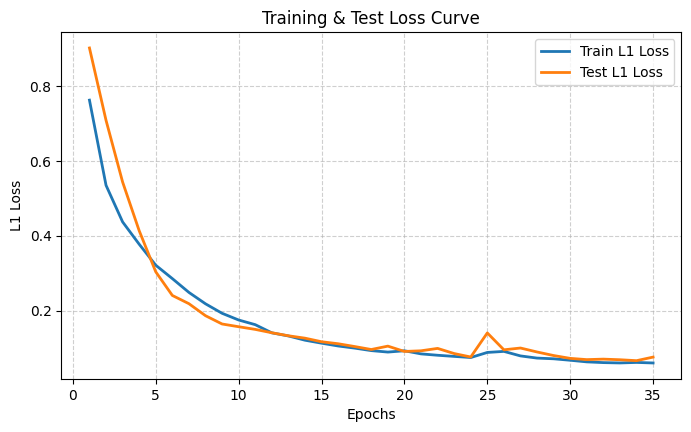

In [9]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, epochs + 1), train_losses, label='Train L1 Loss', color='#1f77b4', linewidth=2)
plt.plot(range(1, epochs + 1), test_losses, label='Test L1 Loss', color='#ff7f0e', linewidth=2)
plt.xlabel('Epochs')
plt.ylabel('L1 Loss')
plt.title('Training & Test Loss Curve')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('loss_curve.png', dpi=300)
plt.show()

## 6. การวัดประสิทธิภาพโมเดล (Performance Evaluation)
วัดผลบน Test Set ด้วยค่าเชิงตัวเลข:
- **MAE (Mean Absolute Error):** ยิ่งต่ำยิ่งดี
- **PSNR (Peak Signal-to-Noise Ratio):** ยิ่งสูงยิ่งแสดงถึงความชัดและคุณภาพสีที่ดี (dB)

In [10]:
def calculate_psnr(target, pred):
    mse = np.mean((target - pred) ** 2)
    if mse == 0:
        return 100
    return 20 * math.log10(1.0 / math.sqrt(mse))

model.eval()
all_mae = []
all_psnr = []

with torch.no_grad():
    for sketches, colors, names in test_loader:
        sketches = sketches.to(device)
        colors = colors.to(device)
        outputs = model(sketches)

        for i in range(sketches.size(0)):
            pred_img = denormalize(outputs[i])
            target_img = denormalize(colors[i])

            mae = np.mean(np.abs(target_img - pred_img))
            psnr = calculate_psnr(target_img, pred_img)

            all_mae.append(mae)
            all_psnr.append(psnr)

print('=== ผลการวัดประสิทธิภาพบน Test Set ===')
print(f'Average MAE:  {np.mean(all_mae):.4f}')
print(f'Average PSNR: {np.mean(all_psnr):.2f} dB')

=== ผลการวัดประสิทธิภาพบน Test Set ===
Average MAE:  0.0378
Average PSNR: 19.26 dB


## 7. ผลลัพธ์ที่ได้ (Qualitative Results - ภาพที่เติมสี)
แสดงภาพเปรียบเทียบ 3 ส่วน:
1. **Input Sketch:** ภาพสเก็ตที่ป้อนให้โมเดล
2. **Model Output:** ภาพสีที่โมเดลเติมสีให้อัตโนมัติ
3. **Target (Ground Truth):** ภาพสีเป้าหมายจริง

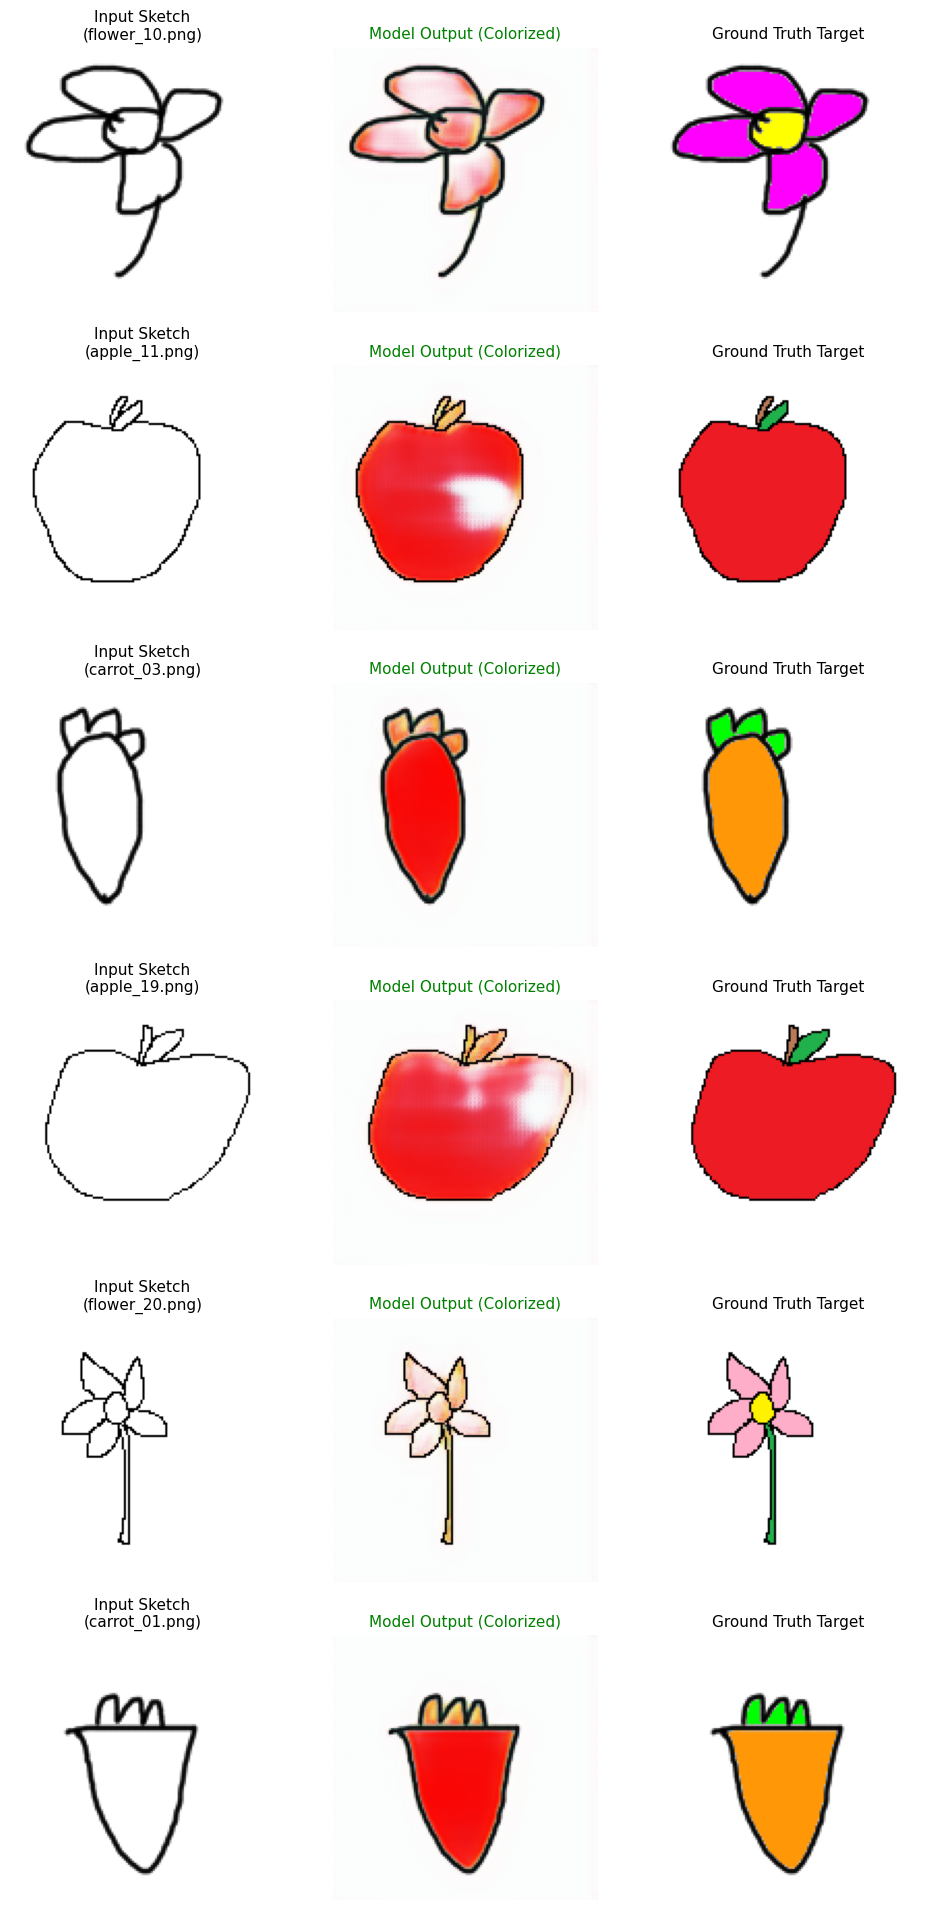

 บันทึกภาพผลลัพธ์: colorization_results.png


In [11]:
model.eval()
num_show = min(6, len(test_dataset))
fig, axes = plt.subplots(num_show, 3, figsize=(10, 3.2 * num_show))

with torch.no_grad():
    for i in range(num_show):
        s_tensor, c_tensor, name = test_dataset[i]
        input_batch = s_tensor.unsqueeze(0).to(device)
        pred_batch = model(input_batch)

        s_img = denormalize(s_tensor)
        c_img = denormalize(c_tensor)
        p_img = denormalize(pred_batch[0])

        ax_row = axes[i] if num_show > 1 else axes

        ax_row[0].imshow(s_img)
        ax_row[0].set_title(f'Input Sketch\n({name})', fontsize=11)
        ax_row[0].axis('off')

        ax_row[1].imshow(p_img)
        ax_row[1].set_title('Model Output (Colorized)', fontsize=11, color='green')
        ax_row[1].axis('off')

        ax_row[2].imshow(c_img)
        ax_row[2].set_title('Ground Truth Target', fontsize=11)
        ax_row[2].axis('off')

plt.tight_layout()
plt.savefig('colorization_results.png', dpi=300)
plt.show()
print(' บันทึกภาพผลลัพธ์: colorization_results.png')

### แสดงผลการทำนายทั้งหมดบน Test Set (ทั้ง 12 ภาพ)

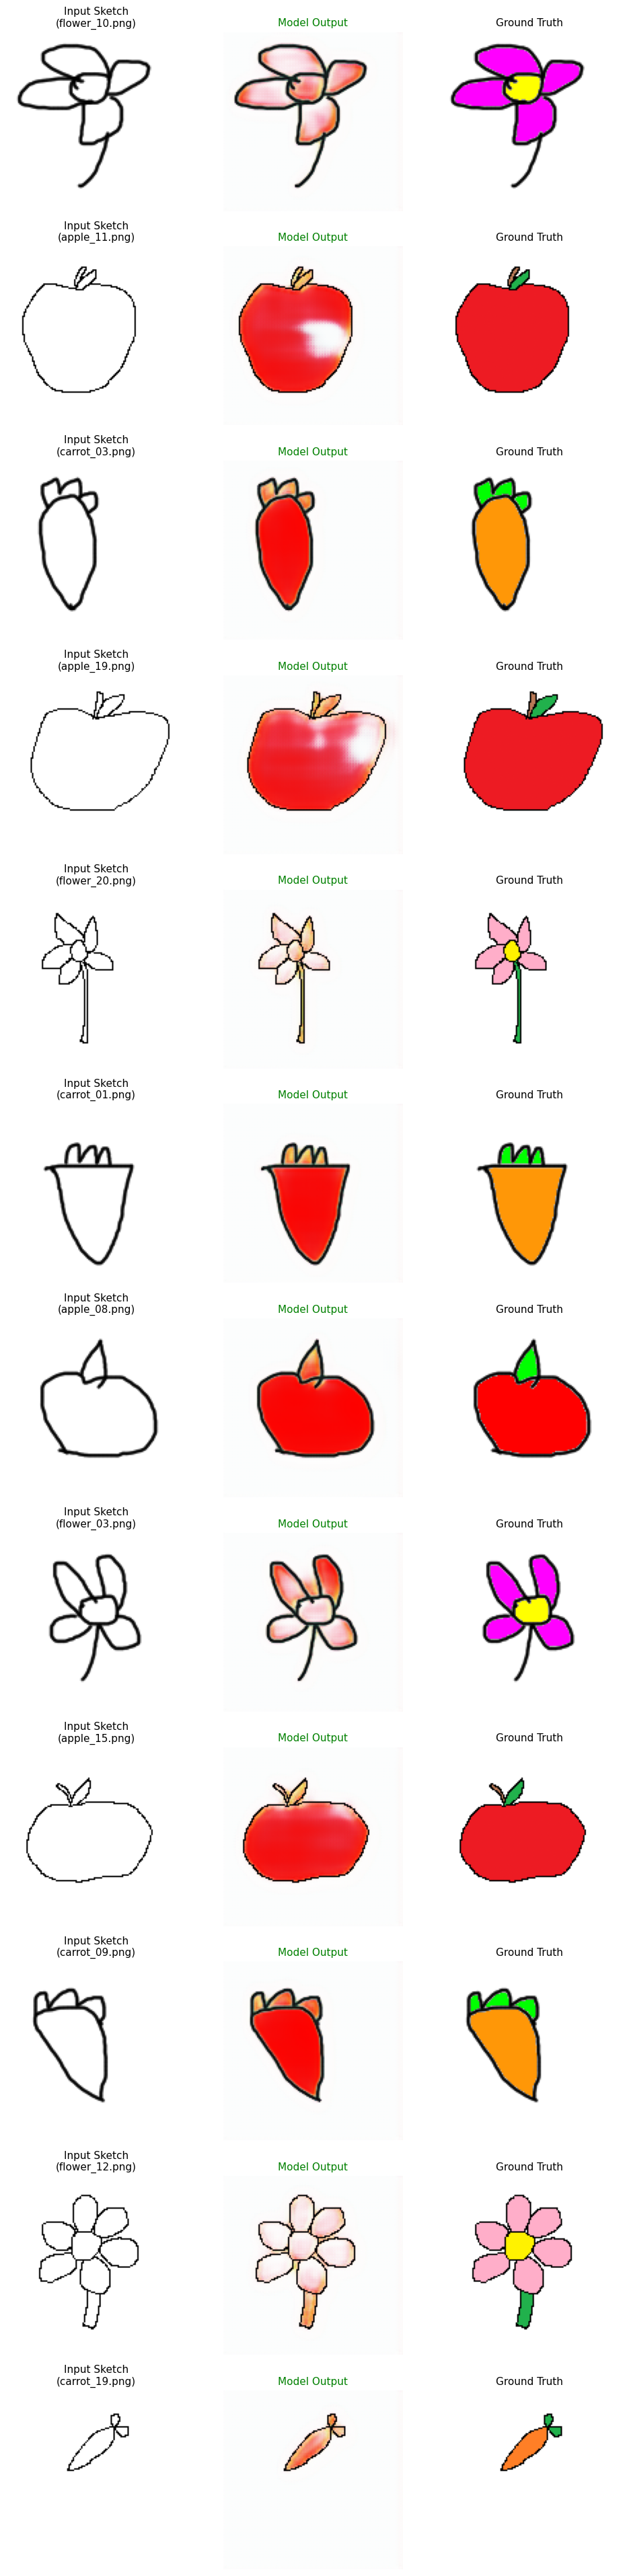

In [12]:
model.eval()
num_test_images = len(test_dataset)
fig, axes = plt.subplots(num_test_images, 3, figsize=(10, 3.2 * num_test_images))

with torch.no_grad():
    for i in range(num_test_images):
        s_tensor, c_tensor, name = test_dataset[i]
        input_batch = s_tensor.unsqueeze(0).to(device)
        pred_batch = model(input_batch)

        s_img = denormalize(s_tensor)
        c_img = denormalize(c_tensor)
        p_img = denormalize(pred_batch[0])

        ax_row = axes[i] if num_test_images > 1 else axes

        ax_row[0].imshow(s_img)
        ax_row[0].set_title(f'Input Sketch\n({name})', fontsize=11)
        ax_row[0].axis('off')

        ax_row[1].imshow(p_img)
        ax_row[1].set_title('Model Output', fontsize=11, color='green')
        ax_row[1].axis('off')

        ax_row[2].imshow(c_img)
        ax_row[2].set_title('Ground Truth', fontsize=11)
        ax_row[2].axis('off')

plt.tight_layout()
plt.show()